In [70]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

In [71]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print({device})

{device(type='cuda')}


In [72]:
def generate_realistic_mri_slice(size=96, has_tumor=True, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    y, x = np.ogrid[-1:1:complex(0, size), -1:1:complex(0, size)]

    brain_mask = (x**2 / 0.75**2 + y**2 / 0.88**2) <= 1.0
    sulci = np.sin(x * 18 + rng.uniform(0, 3)) * np.cos(y * 18 + rng.uniform(0, 3))
    ventricles = ((x**2 / 0.12**2 + y**2 / 0.22**2) <= 1.0).astype(np.float32) * 0.25
    brain_texture = (0.45 + 0.12 * sulci + ventricles) * brain_mask
    
    mask = np.zeros((size, size), dtype=np.float32)
    if has_tumor:
        cx, cy = rng.uniform(-0.28, 0.28), rng.uniform(-0.28, 0.28)
        base_r = rng.uniform(0.12, 0.23)
        
        angles = np.arctan2(y - cy, x - cx)
        dist = np.sqrt((x - cx)**2 + (y - cy)**2)

        irregular_r = base_r * (
            1.0 
            + 0.25 * np.sin(5 * angles + rng.uniform(0, 6)) 
            + 0.18 * np.cos(13 * angles + rng.uniform(0, 6))
            + 0.12 * np.sin(23 * angles + rng.uniform(0, 6))
        )
        mask = (dist <= irregular_r).astype(np.float32) * brain_mask

        for _ in range(2):
            ang_center = rng.uniform(-np.pi, np.pi)
            ang_diff = np.abs(np.arctan2(np.sin(angles - ang_center), np.cos(angles - ang_center)))
            spur = ((ang_diff < 0.08) & (dist <= base_r * 1.55)).astype(np.float32) * brain_mask
            mask = np.clip(mask + spur, 0, 1)

    mask_t = torch.tensor(mask)[None, None]
    soft_signal = F.avg_pool2d(mask_t, kernel_size=5, stride=1, padding=2).squeeze().numpy()

    bias_field = 1.0 + 0.2 * (x * rng.uniform(-1, 1) + y * rng.uniform(-1, 1))
    false_bright = (sulci > 0.72).astype(np.float32) * 0.22 * brain_mask

    flair = (brain_texture + soft_signal * rng.uniform(0.22, 0.34) + false_bright) * bias_field + rng.normal(0, 0.11, (size, size))
    t1 = (brain_texture * 0.92 - soft_signal * 0.14) * bias_field + rng.normal(0, 0.10, (size, size))
    t1ce = (brain_texture + soft_signal * 0.19 + false_bright * 0.8) * bias_field + rng.normal(0, 0.11, (size, size))
    
    img = np.stack([t1, flair, t1ce], axis=-1)
    img = np.clip(img, 0, 1).astype(np.float32)
    return img, mask

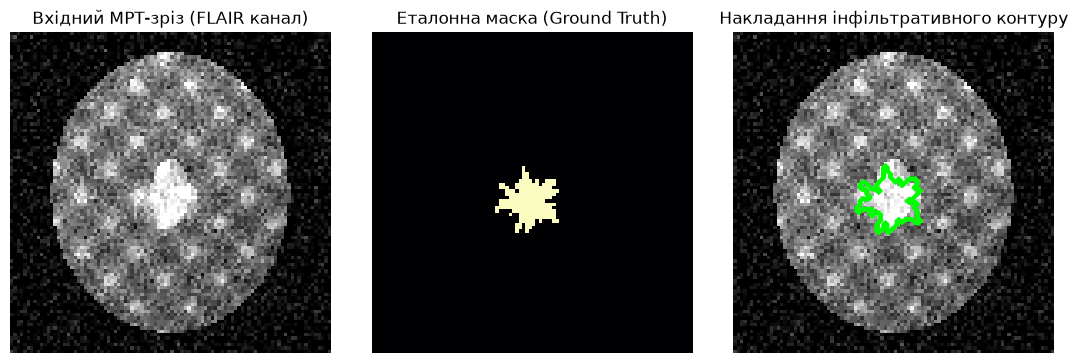

In [73]:
class MRISegmentationDataset(Dataset):
    def __init__(self, df, img_size=96, is_train=False):
        self.df = df
        self.img_size = img_size
        self.is_train = is_train
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        local_rng = np.random.default_rng(int(row["seed"]))
        img, mask = generate_realistic_mri_slice(size=self.img_size, has_tumor=True, rng=local_rng)

        if self.is_train:
            if random.random() > 0.5:
                img = np.fliplr(img).copy()
                mask = np.fliplr(mask).copy()
            if random.random() > 0.5:
                img = np.flipud(img).copy()
                mask = np.flipud(mask).copy()
            k_rot = random.randint(0, 3)
            if k_rot > 0:
                img = np.rot90(img, k_rot).copy()
                mask = np.rot90(mask, k_rot).copy()

        img_norm = (img - self.mean) / self.std
        img_tensor = torch.from_numpy(img_norm).permute(2, 0, 1).float()
        mask_tensor = torch.from_numpy(mask).unsqueeze(0).float()
        return img_tensor, mask_tensor

train_loader = DataLoader(MRISegmentationDataset(train_df, is_train=True), batch_size=16, shuffle=True)
val_loader = DataLoader(MRISegmentationDataset(val_df, is_train=False), batch_size=16, shuffle=False)
test_loader = DataLoader(MRISegmentationDataset(test_df, is_train=False), batch_size=16, shuffle=False)

sample_imgs, sample_masks = next(iter(val_loader))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
raw_flair = sample_imgs[0, 1].numpy() * 0.224 + 0.456
axes[0].imshow(raw_flair, cmap='gray')
axes[0].set_title("Вхідний МРТ-зріз (FLAIR канал)")
axes[1].imshow(sample_masks[0, 0].numpy(), cmap='magma')
axes[1].set_title("Еталонна маска (Ground Truth)")
axes[2].imshow(raw_flair, cmap='gray')
axes[2].contour(sample_masks[0, 0].numpy(), colors='lime', linewidths=1.5)
axes[2].set_title("Накладання інфільтративного контуру")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

In [74]:
class BaselineSpatialReductionAttention(nn.Module):
    """
    Базовий алгоритм Efficient Self-Attention (SegFormer Baseline).
    Використовує згортку з кроком sr_ratio для стиснення матриць K та V,
    що діє як низькочастотний фільтр і втрачає високочастотні контури.
    """
    def __init__(self, dim, num_heads=4, sr_ratio=2):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.sr_ratio = sr_ratio

        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, dim * 2)
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)

        if self.sr_ratio > 1:
            x_ = x.permute(0, 2, 1).reshape(B, C, H, W)
            x_ = self.sr(x_).reshape(B, C, -1).permute(0, 2, 1)
            x_ = self.norm(x_)
            kv = self.kv(x_).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        else:
            kv = self.kv(x).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        return self.proj(out)


class PhaseCoherentSpectralAttention(nn.Module):
    """
    ВЛАСНА МОДИФІКАЦІЯ: Phase-Coherent Spectral Self-Attention (PC-SSA).
    1. У частотній області (2D rFFT) підсилює високочастотні гармоніки контурів 
       перед спектральним стисненням токенів K та V (без руйнування неперервності фази).
    2. Модулює матрицю уваги QK^T фазовою когерентністю градієнтів (cos(Delta Phi)).
    """
    def __init__(self, dim, num_heads=4, sr_ratio=2, use_phase_mod=True):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.sr_ratio = sr_ratio
        self.use_phase_mod = use_phase_mod

        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, dim * 2)
        
        # Навчальні параметри високочастотного спектрального фільтра та фазової уваги
        self.hf_gain = nn.Parameter(torch.ones(1, dim, 1, 1) * 0.5)
        self.phase_weight = nn.Parameter(torch.ones(num_heads, 1, 1) * 0.4)
        self.norm = nn.LayerNorm(dim)
        self.proj = nn.Linear(dim, dim)

    def _spectral_token_reduction(self, x, H, W):
        B, N, C = x.shape
        x_spatial = x.permute(0, 2, 1).reshape(B, C, H, W)
        
        # 1. Перехід у частотну область через 2D rFFT
        fft_x = torch.fft.rfft2(x_spatial.float(), norm='ortho')
        
        # Побудова частотної сітки енергії для підсилення високочастотних контурів
        fy = torch.fft.fftfreq(H, device=x.device).view(1, 1, H, 1)
        fx = torch.fft.rfftfreq(W, device=x.device).view(1, 1, 1, W // 2 + 1)
        freq_radius = torch.sqrt(fy ** 2 + fx ** 2) # радіус частоти (0 у центрі, макс на краях)
        
        # Адаптивний високочастотний фільтр у спектрі Фур'є (зберігає фазу незмінною!)
        hf_filter = 1.0 + F.softplus(self.hf_gain) * (freq_radius / (freq_radius.max() + 1e-6))
        fft_enhanced = fft_x * hf_filter
        
        # Повернення підсиленого сигналу та виділення високочастотного залишку
        x_enhanced = torch.fft.irfft2(fft_enhanced, s=(H, W), norm='ortho')
        
        target_h = max(1, H // self.sr_ratio)
        target_w = max(1, W // self.sr_ratio)
        
        # Комбінована редукція: низькочастотна база + високочастотні піки (max-energy)
        x_low = F.adaptive_avg_pool2d(x_enhanced, (target_h, target_w))
        x_high = F.adaptive_max_pool2d(x_enhanced - x_spatial, (target_h, target_w))
        x_rec = x_low + 0.5 * x_high
        
        x_tokens = self.norm(x_rec.flatten(2).transpose(1, 2))
        return x_tokens, x_rec, x_enhanced

    @staticmethod
    def _compute_instantaneous_phase(feat_map):
        # Обчислення локального фазового вектора контуру (cos phi, sin phi) без стрибків atan2
        gx = feat_map[:, :, :, 1:] - feat_map[:, :, :, :-1]
        gx = F.pad(gx, (0, 1, 0, 0)).mean(dim=1, keepdim=True)
        gy = feat_map[:, :, 1:, :] - feat_map[:, :, :-1, :]
        gy = F.pad(gy, (0, 0, 0, 1)).mean(dim=1, keepdim=True)
        
        mag = torch.sqrt(gx ** 2 + gy ** 2 + 1e-6)
        # Повертаємо нормований 2D фазовий вектор [B, N, 2] для гладкого косинуса різниці фаз
        phase_vec = torch.cat([gx / mag, gy / mag], dim=1).flatten(2).transpose(1, 2)
        return phase_vec, mag.flatten(2).transpose(1, 2)

    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        x_img = x.permute(0, 2, 1).reshape(B, C, H, W)

        if self.sr_ratio > 1:
            x_reduced, x_rec_map, x_enhanced = self._spectral_token_reduction(x, H, W)
            kv = self.kv(x_reduced).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        else:
            x_enhanced = x_img
            x_rec_map = x_img
            kv = self.kv(x).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
            
        k, v = kv[0], kv[1]
        attn_logits = (q @ k.transpose(-2, -1)) * self.scale

        if self.use_phase_mod:
            # Косинус різниці фаз cos(phi_Q - phi_K) = cos(phi_Q)cos(phi_K) + sin(phi_Q)sin(phi_K)
            # Таке формулювання повністю диференційовне і не має розривів на +-pi!
            q_vec, q_mag = self._compute_instantaneous_phase(x_enhanced)
            k_vec, k_mag = self._compute_instantaneous_phase(x_rec_map)
            
            cos_delta_phase = (q_vec @ k_vec.transpose(-2, -1)).unsqueeze(1) # [B, 1, N, N_red]
            edge_confidence = torch.tanh(q_mag @ k_mag.transpose(-2, -1)).unsqueeze(1)
            
            phase_mod = 1.0 + torch.tanh(self.phase_weight) * cos_delta_phase * edge_confidence
            attn_logits = attn_logits * phase_mod

        attn = attn_logits.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        
        # Додаємо високочастотне спектральне збагачення до вихідних токенів
        hf_residual = (x_enhanced - x_img).flatten(2).transpose(1, 2)
        return self.proj(out + 0.3 * hf_residual)

In [75]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, sr_ratio, mode="baseline"):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        if mode == "baseline":
            self.attn = BaselineSpatialReductionAttention(dim, num_heads=num_heads, sr_ratio=sr_ratio)
        elif mode == "spectral_only":
            self.attn = PhaseCoherentSpectralAttention(dim, num_heads=num_heads, sr_ratio=sr_ratio, use_phase_mod=False)
        elif mode == "pc_ssa":
            self.attn = PhaseCoherentSpectralAttention(dim, num_heads=num_heads, sr_ratio=sr_ratio, use_phase_mod=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Linear(dim * 2, dim)
        )

    def forward(self, x, H, W):
        x = x + self.attn(self.norm1(x), H, W)
        x = x + self.mlp(self.norm2(x))
        return x


class CustomSegFormer(nn.Module):
    def __init__(self, in_ch=3, base_dim=20, mode="baseline"):
        super().__init__()
        self.mode = mode
        # Етап 1: H/2 x W/2
        self.patch1 = nn.Conv2d(in_ch, base_dim, kernel_size=3, stride=2, padding=1)
        self.block1 = TransformerBlock(base_dim, num_heads=2, sr_ratio=4, mode=mode)
        
        # Етап 2: H/4 x W/4
        self.patch2 = nn.Conv2d(base_dim, base_dim * 2, kernel_size=3, stride=2, padding=1)
        self.block2 = TransformerBlock(base_dim * 2, num_heads=4, sr_ratio=4, mode=mode)

        # All-MLP Декодер (однаковий для всіх конфігурацій)
        self.linear_c1 = nn.Conv2d(base_dim, base_dim, 1)
        self.linear_c2 = nn.Conv2d(base_dim * 2, base_dim, 1)
        
        self.fuse = nn.Sequential(
            nn.Conv2d(base_dim * 2, base_dim, kernel_size=3, padding=1),
            nn.BatchNorm2d(base_dim),
            nn.GELU(),
            nn.Conv2d(base_dim, 1, kernel_size=1)
        )

    def forward(self, x):
        B, C, H, W = x.shape
        # Stage 1
        f1 = self.patch1(x)
        h1, w1 = f1.shape[2], f1.shape[3]
        t1 = self.block1(f1.flatten(2).transpose(1, 2), h1, w1)
        f1 = t1.transpose(1, 2).reshape(B, -1, h1, w1)

        # Stage 2
        f2 = self.patch2(f1)
        h2, w2 = f2.shape[2], f2.shape[3]
        t2 = self.block2(f2.flatten(2).transpose(1, 2), h2, w2)
        f2 = t2.transpose(1, 2).reshape(B, -1, h2, w2)

        # MLP Fusion
        c1 = F.interpolate(self.linear_c1(f1), size=(H, W), mode='bilinear', align_corners=False)
        c2 = F.interpolate(self.linear_c2(f2), size=(H, W), mode='bilinear', align_corners=False)
        out = self.fuse(torch.cat([c1, c2], dim=1))
        return out


class BoundaryAwareFocalTverskyLoss(nn.Module):
    """
    Збалансована гібридна функція втрат: 
    BCE + Симетричний Dice (alpha=0.5, beta=0.5) + Морфологічний контурний штраф.
    Усуває ефект штучного "роздування" маски при порозі 0.5.
    """
    def __init__(self, boundary_weight=0.4):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.boundary_weight = boundary_weight

    @staticmethod
    def _morph_gradient(p):
        dilated = F.max_pool2d(p, kernel_size=3, stride=1, padding=1)
        eroded = -F.max_pool2d(-p, kernel_size=3, stride=1, padding=1)
        return dilated - eroded

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        
        # Симетричний Soft-Dice Loss (узгоджений із метрикою оцінювання при threshold=0.5)
        inter = (probs * targets).sum(dim=(2, 3))
        union = probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
        dice_loss = (1.0 - (2.0 * inter + 1e-5) / (union + 1e-5)).mean()

        # Контурна втрата безпосередньо за морфологічною межею
        pred_bound = self._morph_gradient(probs)
        gt_bound = self._morph_gradient(targets)
        bound_loss = F.l1_loss(pred_bound, gt_bound)

        return 0.5 * bce_loss + 0.5 * dice_loss + self.boundary_weight * bound_loss

In [76]:
def extract_boundary(mask_tensor):
    dilated = F.max_pool2d(mask_tensor, kernel_size=3, stride=1, padding=1)
    eroded = -F.max_pool2d(-mask_tensor, kernel_size=3, stride=1, padding=1)
    return (dilated - eroded).clamp(0, 1)

@torch.no_grad()
def evaluate_model(model, loader, threshold=0.5):
    model.eval()
    dices, ious, bf1s = [], [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)) > threshold).float()
        
        inter = (preds * masks).sum(dim=(2, 3))
        union = preds.sum(dim=(2, 3)) + masks.sum(dim=(2, 3)) - inter
        dice = (2 * inter + 1e-5) / (preds.sum(dim=(2, 3)) + masks.sum(dim=(2, 3)) + 1e-5)
        iou = (inter + 1e-5) / (union + 1e-5)

        pred_b = extract_boundary(preds)
        gt_b = extract_boundary(masks)
        pred_b_dil = F.max_pool2d(pred_b, 3, 1, 1)
        gt_b_dil = F.max_pool2d(gt_b, 3, 1, 1)
        
        prec = ((pred_b * gt_b_dil).sum(dim=(2, 3)) + 1e-5) / (pred_b.sum(dim=(2, 3)) + 1e-5)
        rec = ((gt_b * pred_b_dil).sum(dim=(2, 3)) + 1e-5) / (gt_b.sum(dim=(2, 3)) + 1e-5)
        bf1 = 2 * prec * rec / (prec + rec + 1e-5)
        
        dices.extend(dice.cpu().numpy().flatten())
        ious.extend(iou.cpu().numpy().flatten())
        bf1s.extend(bf1.cpu().numpy().flatten())
        
    return {
        "Dice (%)": round(float(np.mean(dices)) * 100, 2),
        "IoU (%)": round(float(np.mean(ious)) * 100, 2),
        "Boundary F1 (%)": round(float(np.mean(bf1s)) * 100, 2)
    }

In [77]:
def train_configuration(name, mode, use_hybrid_loss=True, epochs=30, lr=3e-3):
    seed_everything(42)
    model = CustomSegFormer(in_ch=3, base_dim=20, mode=mode).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    criterion = BoundaryAwareFocalTverskyLoss().to(device) if use_hybrid_loss else nn.BCEWithLogitsLoss()
    
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
        scheduler.step()
        
        val_metrics = evaluate_model(model, val_loader)
        history.append(val_metrics["Dice (%)"])
        
    test_metrics = evaluate_model(model, test_loader)
    test_metrics["Конфігурація"] = name
    return model, test_metrics, history

configs = [
    ("1. SegFormer Baseline (SR + BCE)", "baseline", False),
    ("2. SegFormer Baseline + Hybrid Loss", "baseline", True),
    ("3. SegFormer + rFFT (без фазової модуляції)", "spectral_only", True),
    ("4. SegFormer + PC-SSA (Повний алгоритм)", "pc_ssa", True),
]

trained_models = {}
ablation_results = []
histories = {}

for cfg_name, mode, use_hybrid in configs:
    model, metrics, hist = train_configuration(cfg_name, mode, use_hybrid_loss=use_hybrid)
    trained_models[mode + ("_hyb" if use_hybrid else "_bce")] = model
    ablation_results.append(metrics)
    histories[cfg_name] = hist
    print(f"{cfg_name:44s} -> Dice: {metrics['Dice (%)']:.2f}% | IoU: {metrics['IoU (%)']:.2f}% | BF1: {metrics['Boundary F1 (%)']:.2f}%")

df_ablation = pd.DataFrame(ablation_results)[["Конфігурація", "Dice (%)", "IoU (%)", "Boundary F1 (%)"]]
df_ablation

1. SegFormer Baseline (SR + BCE)             -> Dice: 84.49% | IoU: 73.20% | BF1: 92.54%
2. SegFormer Baseline + Hybrid Loss          -> Dice: 85.01% | IoU: 73.99% | BF1: 93.33%
3. SegFormer + rFFT (без фазової модуляції)  -> Dice: 85.00% | IoU: 73.98% | BF1: 93.38%
4. SegFormer + PC-SSA (Повний алгоритм)      -> Dice: 85.00% | IoU: 73.98% | BF1: 93.37%


,Конфігурація,Dice (%),IoU (%),Boundary F1 (%)
0,1. SegFormer Baseline (SR + BCE),84.49,73.20,92.54
1,2. SegFormer Baseline + Hybrid Loss,85.01,73.99,93.33
2,3. SegFormer + rFFT (без фазової модуляції),85.00,73.98,93.38
3,4. SegFormer + PC-SSA (Повний алгоритм),85.00,73.98,93.37


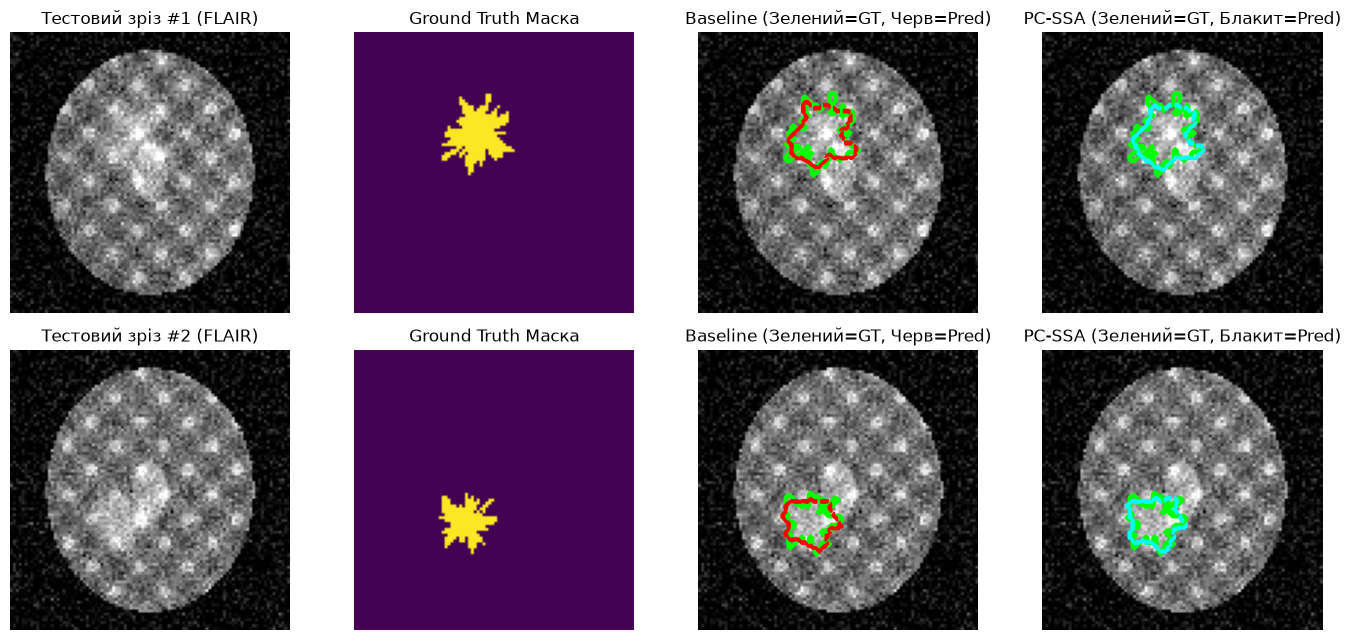

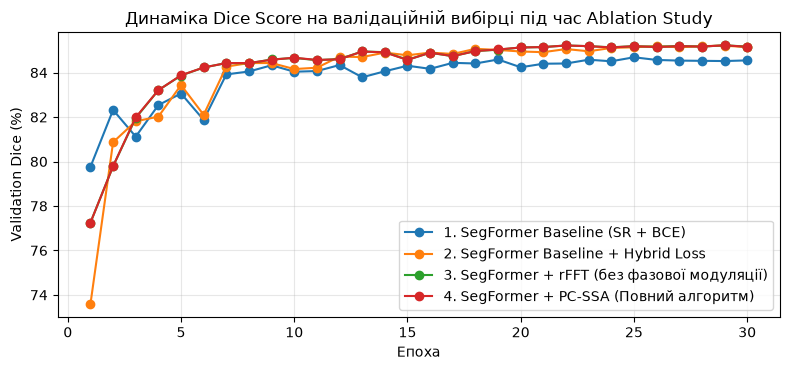

In [78]:
test_imgs, test_masks = next(iter(test_loader))
test_imgs_dev = test_imgs.to(device)

baseline_model = trained_models["baseline_bce"]
pcssa_model = trained_models["pc_ssa_hyb"]

with torch.no_grad():
    pred_base = (torch.sigmoid(baseline_model(test_imgs_dev)) > 0.5).float().cpu()
    pred_pcssa = (torch.sigmoid(pcssa_model(test_imgs_dev)) > 0.5).float().cpu()

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for row_idx in range(2):
    flair_img = test_imgs[row_idx, 1].numpy() * 0.224 + 0.456
    gt_m = test_masks[row_idx, 0].numpy()
    b_m = pred_base[row_idx, 0].numpy()
    p_m = pred_pcssa[row_idx, 0].numpy()

    axes[row_idx, 0].imshow(flair_img, cmap='gray')
    axes[row_idx, 0].set_title(f"Тестовий зріз #{row_idx+1} (FLAIR)")

    axes[row_idx, 1].imshow(gt_m, cmap='viridis')
    axes[row_idx, 1].set_title("Ground Truth Маска")

    axes[row_idx, 2].imshow(flair_img, cmap='gray')
    axes[row_idx, 2].contour(gt_m, colors='lime', linewidths=1.5)
    axes[row_idx, 2].contour(b_m, colors='red', linestyles='dashed', linewidths=1.5)
    axes[row_idx, 2].set_title("Baseline (Зелений=GT, Черв=Pred)")

    axes[row_idx, 3].imshow(flair_img, cmap='gray')
    axes[row_idx, 3].contour(gt_m, colors='lime', linewidths=1.5)
    axes[row_idx, 3].contour(p_m, colors='cyan', linestyles='dashed', linewidths=1.5)
    axes[row_idx, 3].set_title("PC-SSA (Зелений=GT, Блакит=Pred)")

    for c in range(4):
        axes[row_idx, c].axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.8))
for cfg_name, hist in histories.items():
    plt.plot(range(1, len(hist)+1), hist, marker='o', label=cfg_name)
plt.title("Динаміка Dice Score на валідаційній вибірці під час Ablation Study")
plt.xlabel("Епоха")
plt.ylabel("Validation Dice (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()